In [1]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

## Settings

In [2]:
# Visual style settings
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 11

APPROACHES_CONFIG = [
    {'det': 'yolov8n', 'trk': 'bytetrack', 'name': 'YOLOv8n + ByteTrack'},
    {'det': 'yolov8n', 'trk': 'botsort', 'name': 'YOLOv8n + BoT-SORT'},
    {'det': 'yolov8s', 'trk': 'bytetrack', 'name': 'YOLOv8s + ByteTrack'},
    {'det': 'yolov8s', 'trk': 'botsort', 'name': 'YOLOv8s + BoT-SORT'},
]

## Paths resolving and preparation

In [3]:
# The split used to aggregate results
SPLIT = 'dev'  # Can be changed by 'test' for test split

script_path = Path().resolve()
# If the code was launched from the root folder or from 'scripts/', determine the root dynamically
ROOT_DIR = (
    script_path.parent.parent
    if (script_path.parent.name == 'scripts' or script_path.name == 'results')
    else script_path.parent
)
if ROOT_DIR.name == 'scripts' or not (ROOT_DIR / 'reports').exists():
  # if the root is the current folder or a level upper
  ROOT_DIR = script_path if (script_path / 'reports').exists() else script_path.parent

reports_dir = ROOT_DIR / 'reports'
tracks_dir = ROOT_DIR / 'outputs' / 'tracks' / SPLIT

# Path for saving charts and tables
output_dir = script_path / 'results'
output_dir.mkdir(parents=True, exist_ok=True)

## Directoty existence checking

In [4]:
if not reports_dir.exists():
  raise FileNotFoundError(
      f'Detector reports directory "{reports_dir}" not found in the project root, run the evaluation scripts'
  )

if not tracks_dir.exists():
  raise FileNotFoundError(
      f'Tracks directory "{tracks_dir}" not found, run run_tracking.py'
  )

## Tables preparation

In [10]:
rows = []
print(f'Collecting metrics for 4 approaches... Split: {SPLIT.upper()}')

for item in APPROACHES_CONFIG:
  det_name = item['det']
  trk_name = item['trk']
  display_name = item['name']

  # Getting the metrics frop reports
  det_json_path = reports_dir / f'detection_{det_name}_{SPLIT}.json'
  if not det_json_path.exists():
    raise FileNotFoundError(f'Detector report file not found: {det_json_path}, run evaluate_detectors.py for model {det_name}')

  det_data = json.loads(det_json_path.read_text(encoding='utf-8'))

  # Looking for the tracker's timing.json
  matching_dirs = list(tracks_dir.glob(f'{det_name}_{trk_name}_*'))
  if not matching_dirs:
    raise FileNotFoundError(
        f'Tracking results folder not found for the approach "{display_name}" в {tracks_dir}, run run_tracking.py with correspinding arguments'
    )

  # We take the most recent directory if there are several
  target_track_dir = max(matching_dirs, key=lambda p: p.stat().st_mtime)
  timing_file = target_track_dir / 'timing.json'

  if not timing_file.exists():
    raise FileNotFoundError(f'The timing.json file is missing from the directory {target_track_dir}')

  t_data = json.loads(timing_file.read_text(encoding='utf-8'))

  # Metrics evaluation
  map_50 = float(det_data.get('mAP@0.5', 0) or 0) * 100
  map_50_95 = float(det_data.get('mAP@0.5:0.95', 0) or 0) * 100
  fps = float(t_data.get('fps', 0))
  latency_ms = float(t_data.get('total_ms_per_frame', 0))

  rows.append({
      'Approach': display_name,
      'mAP_50': round(map_50, 2),
      'mAP_50_95': round(map_50_95, 2),
      'FPS': round(fps, 2),
      'Latency_ms': round(latency_ms, 2),
  })

df = pd.DataFrame(rows)

# Printing сomparison table
print('\n' + '=' * 65)
print(' ' * 20 + 'Metrics Comparisson Table')
print('=' * 65)
print(df.to_markdown(index=False))


                    Metrics Comparisson Table
| Approach            |   mAP_50 |   mAP_50_95 |    FPS |   Latency_ms |
|:--------------------|---------:|------------:|-------:|-------------:|
| YOLOv8n + ByteTrack |    58.29 |       42.89 | 144.3  |         6.93 |
| YOLOv8n + BoT-SORT  |    58.29 |       42.89 |  92.46 |        10.82 |
| YOLOv8s + ByteTrack |    61.11 |       46.95 | 109.52 |         9.13 |
| YOLOv8s + BoT-SORT  |    61.11 |       46.95 |  76.01 |        13.16 |


## Plots preparatrion

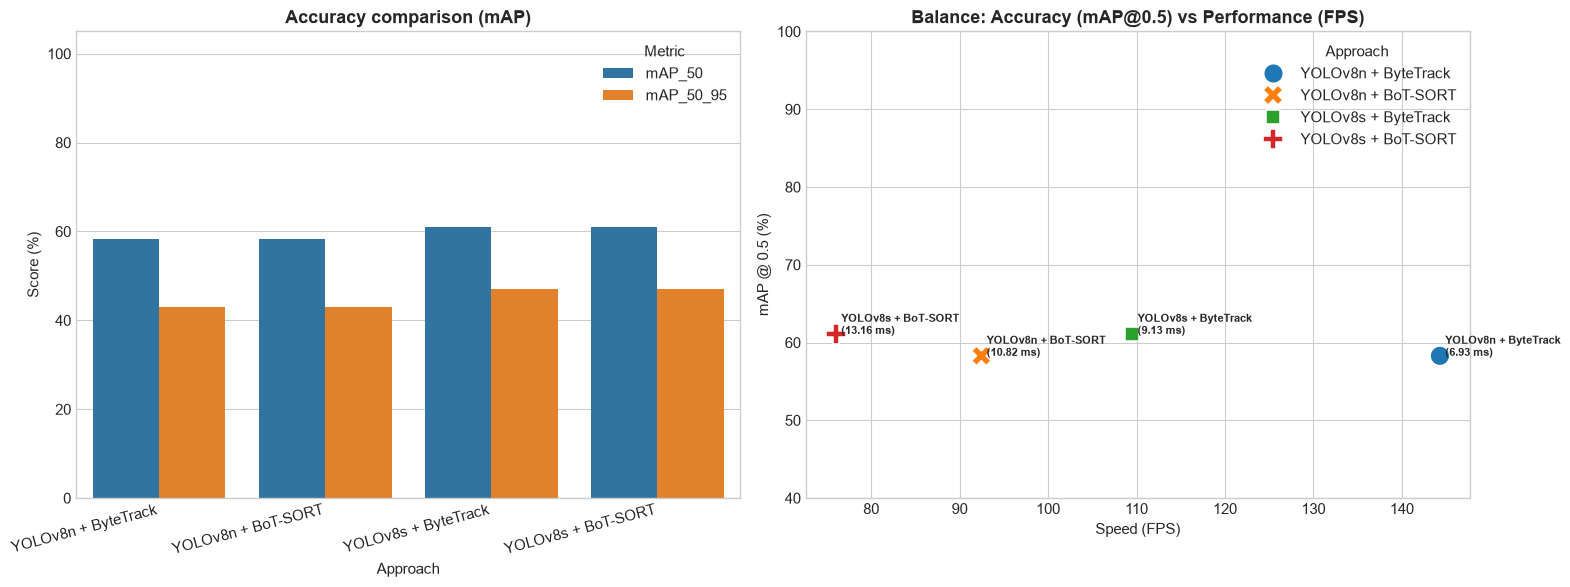

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot for accuracy metrics (mAP@0.5 and mAP@0.5:0.95)
metrics_to_plot = ['mAP_50', 'mAP_50_95']
df_melted = df.melt(
    id_vars='Approach',
    value_vars=metrics_to_plot,
    var_name='Metric',
    value_name='Score (%)',
)

sns.barplot(
    data=df_melted, x='Approach', y='Score (%)', hue='Metric', ax=axes[0]
)
axes[0].set_title('Accuracy comparison (mAP)', fontsize=13, fontweight='bold')
axes[0].set_xticks(range(len(df['Approach'])))
axes[0].set_xticklabels(df['Approach'], rotation=15, ha='right')
axes[0].set_ylim(0, 105)
axes[0].legend(title='Metric')

# График 2: Диаграмма рассеяния Скорость (FPS) vs Качество (mAP@0.5)
sns.scatterplot(
    data=df,
    x='FPS',
    y='mAP_50',
    hue='Approach',
    s=200,
    style='Approach',
    ax=axes[1],
)
axes[1].set_title(
    'Balance: Accuracy (mAP@0.5) vs Performance (FPS)',
    fontsize=13,
    fontweight='bold',
)
axes[1].set_xlabel('Speed (FPS)')
axes[1].set_ylabel('mAP @ 0.5 (%)')
axes[1].set_ylim(40, 100)

# Annotations of points on the graph indicating the delay
for _, row in df.iterrows():
  label_text = f"{row['Approach']}\n({row['Latency_ms']} ms)"
  axes[1].annotate(
      label_text,
      (row['FPS'] + 0.6, row['mAP_50']),
      fontsize=8,
      fontweight='bold',
  )

plt.tight_layout()

plt.show()

## Saving the results

In [7]:
# Saving tables to the results folder
md_path = output_dir / 'metrics_table.md'
tex_path = output_dir / 'metrics_table.tex'

df.to_markdown(md_path, index=False)
with open(tex_path, 'w', encoding='utf-8') as f:
  f.write(
      df.to_latex(
          index=False,
          float_format='%.2f',
          caption=(
              'Comparison of accuracy and performance for four detection and tracking approaches'
          ),
          label='tab:models_comparison',
      )
  )

# Saving the graph to the results folder
output_img = output_dir / 'models_comparison_charts.png'
plt.savefig(output_img, dpi=300, bbox_inches='tight')
print(f'\n Charts successfully saved to file: {output_img}')
print(f'The tables have been exported to files. "{md_path.name}" and "{tex_path.name}"to the directory "{output_dir}"')


 Charts successfully saved to file: C:\Users\User\Desktop\mish\Innopolis\3 курс\Introduction to Computer Vision\pipeline\VehicleDetectionAndTrafficCounting\scripts\results\models_comparison_charts.png
The tables have been exported to files. "metrics_table.md" and "metrics_table.tex"to the directory "C:\Users\User\Desktop\mish\Innopolis\3 курс\Introduction to Computer Vision\pipeline\VehicleDetectionAndTrafficCounting\scripts\results"


<Figure size 640x480 with 0 Axes>